# Khai báo thư viện

In [4]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import math

# Load dữ liệu

In [5]:
train_path = "../data/train.csv"
test_path = "../data/test.csv"

train = pd.read_csv(train_path, low_memory=False)
test = pd.read_csv(test_path, low_memory=False)

df = train.copy()
print("Train Shape:", train.shape)
print("Test Shape:", test.shape)
print("\n Tập train có {} dòng và {} cột".format(train.shape[0], train.shape[1]))
print(train.info())


Train Shape: (1460, 81)
Test Shape: (1459, 80)

 Tập train có 1460 dòng và 81 cột
<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-n

In [6]:
df.head(10)
df.dtypes

Id                 int64
MSSubClass         int64
MSZoning             str
LotFrontage      float64
LotArea            int64
                  ...   
MoSold             int64
YrSold             int64
SaleType             str
SaleCondition        str
SalePrice          int64
Length: 81, dtype: object

# Kiểm tra những biến bị null

## Tập train

In [7]:
print(train.isnull().sum())

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      259
LotArea            0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 81, dtype: int64


## Tập test

In [8]:
print(test.isnull().sum())

Id                 0
MSSubClass         0
MSZoning           4
LotFrontage      227
LotArea            0
                ... 
MiscVal            0
MoSold             0
YrSold             0
SaleType           1
SaleCondition      0
Length: 80, dtype: int64


# Kiếm tra trùng lặp

In [9]:
print("\nSố dòng trùng lặp:", df.duplicated().sum())
print("Số Id trùng lặp:", df["Id"].duplicated().sum())

print("\nCác cột chỉ có trong train:")
print(set(train.columns) - set(test.columns))

print("\nCác cột chỉ có trong test:")
print(set(test.columns) - set(train.columns))


Số dòng trùng lặp: 0
Số Id trùng lặp: 0

Các cột chỉ có trong train:
{'SalePrice'}

Các cột chỉ có trong test:
set()


# Thống kê mô tả

In [10]:
print("\nThống kê mô tả:")
print(df.describe())


Thống kê mô tả:
                Id   MSSubClass  LotFrontage        LotArea  OverallQual  \
count  1460.000000  1460.000000  1201.000000    1460.000000  1460.000000   
mean    730.500000    56.897260    70.049958   10516.828082     6.099315   
std     421.610009    42.300571    24.284752    9981.264932     1.382997   
min       1.000000    20.000000    21.000000    1300.000000     1.000000   
25%     365.750000    20.000000    59.000000    7553.500000     5.000000   
50%     730.500000    50.000000    69.000000    9478.500000     6.000000   
75%    1095.250000    70.000000    80.000000   11601.500000     7.000000   
max    1460.000000   190.000000   313.000000  215245.000000    10.000000   

       OverallCond    YearBuilt  YearRemodAdd   MasVnrArea   BsmtFinSF1  ...  \
count  1460.000000  1460.000000   1460.000000  1452.000000  1460.000000  ...   
mean      5.575342  1971.267808   1984.865753   103.685262   443.639726  ...   
std       1.112799    30.202904     20.645407   181.066207

In [11]:
print("\nThống kê mô tả các biến phân loại:")
print(df.describe(include=["object"]))


Thống kê mô tả các biến phân loại:
       MSZoning Street Alley LotShape LandContour Utilities LotConfig  \
count      1460   1460    91     1460        1460      1460      1460   
unique        5      2     2        4           4         2         5   
top          RL   Pave  Grvl      Reg         Lvl    AllPub    Inside   
freq       1151   1454    50      925        1311      1459      1052   

       LandSlope Neighborhood Condition1  ... GarageType GarageFinish  \
count       1460         1460       1460  ...       1379         1379   
unique         3           25          9  ...          6            3   
top          Gtl        NAmes       Norm  ...     Attchd          Unf   
freq        1382          225       1260  ...        870          605   

       GarageQual GarageCond PavedDrive PoolQC  Fence MiscFeature SaleType  \
count        1379       1379       1460      7    281          54     1460   
unique          5          5          3      3      4           4        9  

C:\Users\toanb\AppData\Local\Temp\ipykernel_10408\1312062369.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.describe(include=["object"]))


In [12]:
print("\nThống kê biến mục tiêu SalePrice:")
print(df["SalePrice"].describe())

print("\nSkewness:", df["SalePrice"].skew())
print("Kurtosis:", df["SalePrice"].kurtosis())


Thống kê biến mục tiêu SalePrice:
count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

Skewness: 1.8828757597682129
Kurtosis: 6.536281860064529


# Trực quan hóa dữ liệu

## Phân loại biến

In [13]:
continuous_cols = [
    'LotFrontage',
    'LotArea',
    'MasVnrArea',
    'BsmtFinSF1',
    'BsmtFinSF2',
    'BsmtUnfSF',
    'TotalBsmtSF',
    '1stFlrSF',
    '2ndFlrSF',
    'LowQualFinSF',
    'GrLivArea',
    'GarageArea',
    'WoodDeckSF',
    'OpenPorchSF',
    'EnclosedPorch',
    '3SsnPorch',
    'ScreenPorch',
    'PoolArea',
    'MiscVal',
    'SalePrice'
]

discrete_cols = [
    'OverallQual',
    'OverallCond',
    'YearBuilt',
    'YearRemodAdd',
    'BsmtFullBath',
    'BsmtHalfBath',
    'FullBath',
    'HalfBath',
    'BedroomAbvGr',
    'KitchenAbvGr',
    'TotRmsAbvGrd',
    'Fireplaces',
    'GarageYrBlt',
    'GarageCars',
    'MoSold',
    'YrSold'
]

nominal_cols = [
    'MSSubClass',
    'MSZoning',
    'Street',
    'Alley',
    'LandContour',
    'Utilities',
    'LotConfig',
    'Neighborhood',
    'Condition1',
    'Condition2',
    'BldgType',
    'HouseStyle',
    'RoofStyle',
    'RoofMatl',
    'Exterior1st',
    'Exterior2nd',
    'MasVnrType',
    'Foundation',
    'Heating',
    'CentralAir',
    'Electrical',
    'GarageType',
    'PavedDrive',
    'MiscFeature',
    'SaleType',
    'SaleCondition'
]

ordinal_cols = [
    'LotShape',
    'LandSlope',
    'ExterQual',
    'ExterCond',
    'BsmtQual',
    'BsmtCond',
    'BsmtExposure',
    'BsmtFinType1',
    'BsmtFinType2',
    'HeatingQC',
    'KitchenQual',
    'Functional',
    'FireplaceQu',
    'GarageFinish',
    'GarageQual',
    'GarageCond',
    'PoolQC',
    'Fence'
]

In [14]:
continuous_cols = [
    c for c in continuous_cols if c in df.columns
]

discrete_cols = [
    c for c in discrete_cols if c in df.columns
]

nominal_cols = [
    c for c in nominal_cols if c in df.columns
]

ordinal_cols = [
    c for c in ordinal_cols if c in df.columns
]

print("Continuous:", len(continuous_cols))
print("Discrete:", len(discrete_cols))
print("Nominal:", len(nominal_cols))
print("Ordinal:", len(ordinal_cols))

Continuous: 20
Discrete: 16
Nominal: 26
Ordinal: 18


## Phân tích đơn biến

### Biến Continuous

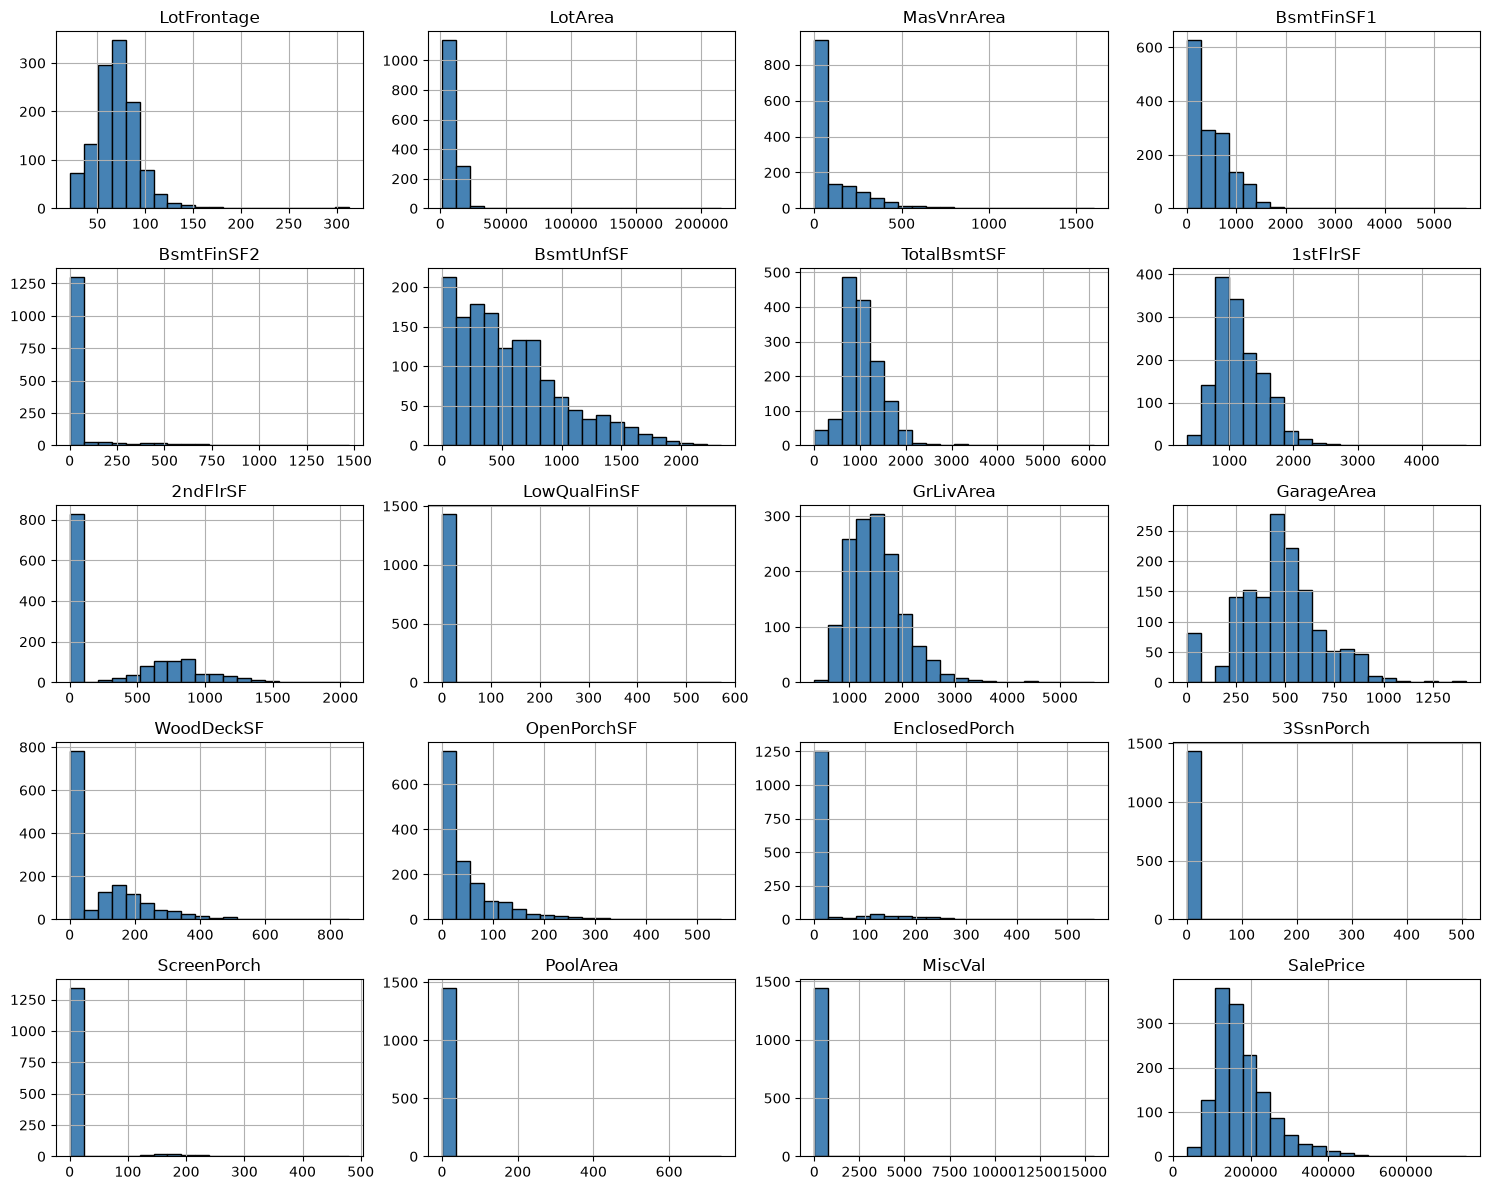

In [15]:
df[continuous_cols].hist(
    bins=20,
    figsize=(15, 12),
    color='steelblue',
    edgecolor='black'
)

plt.tight_layout()
plt.savefig(
    'houseprice_continuous_histogram.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

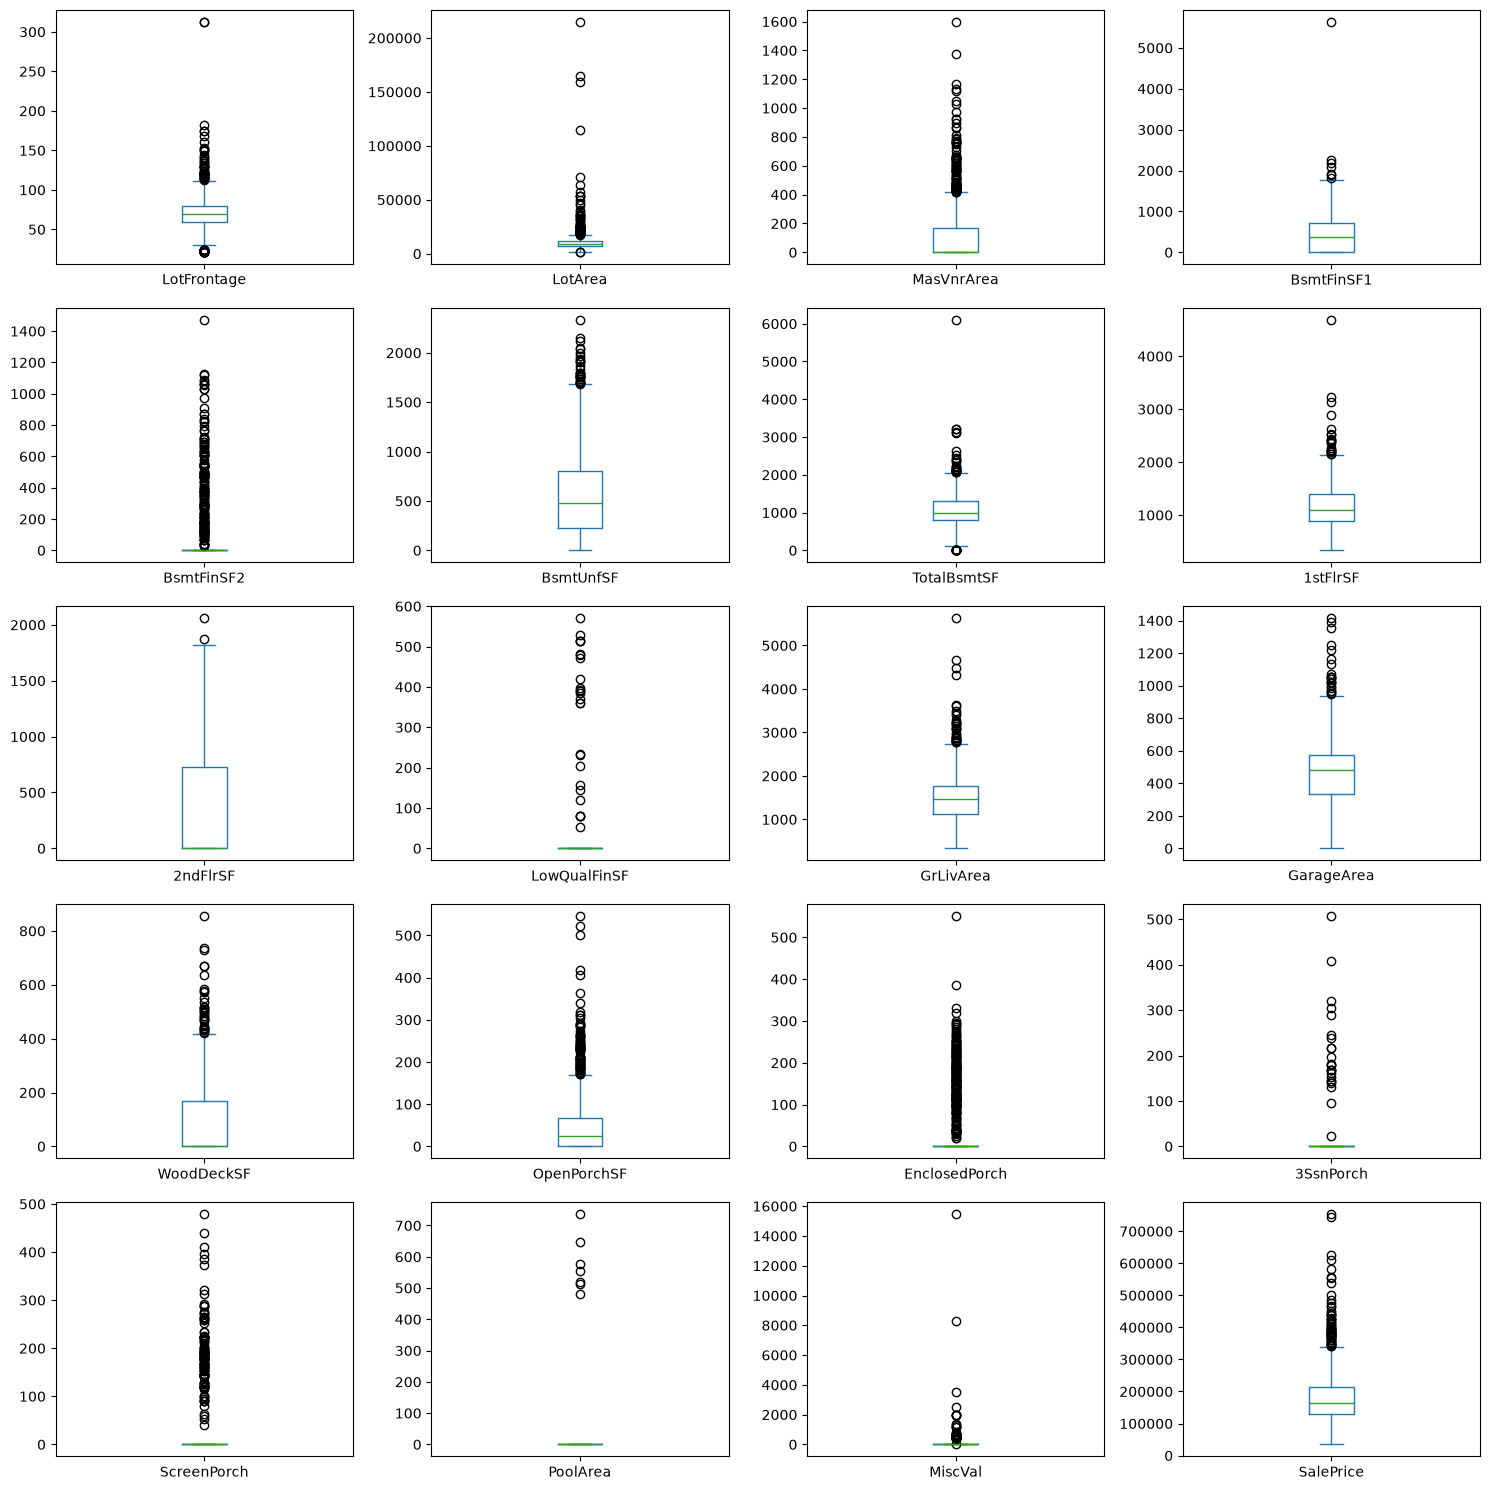

In [16]:
df[continuous_cols].plot(
    kind='box',
    subplots=True,
    layout=(5, 4),
    figsize=(15, 15),
    sharex=False,
    sharey=False
)

plt.tight_layout()
plt.savefig(
    'houseprice_continuous_boxplot.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

### Biến Discrete

In [17]:
print(df[discrete_cols].dtypes)

OverallQual       int64
OverallCond       int64
YearBuilt         int64
YearRemodAdd      int64
BsmtFullBath      int64
BsmtHalfBath      int64
FullBath          int64
HalfBath          int64
BedroomAbvGr      int64
KitchenAbvGr      int64
TotRmsAbvGrd      int64
Fireplaces        int64
GarageYrBlt     float64
GarageCars        int64
MoSold            int64
YrSold            int64
dtype: object


In [18]:
df[discrete_cols] = df[discrete_cols].apply(
    pd.to_numeric,
    errors='coerce'
)

print(df[discrete_cols].dtypes)

OverallQual       int64
OverallCond       int64
YearBuilt         int64
YearRemodAdd      int64
BsmtFullBath      int64
BsmtHalfBath      int64
FullBath          int64
HalfBath          int64
BedroomAbvGr      int64
KitchenAbvGr      int64
TotRmsAbvGrd      int64
Fireplaces        int64
GarageYrBlt     float64
GarageCars        int64
MoSold            int64
YrSold            int64
dtype: object


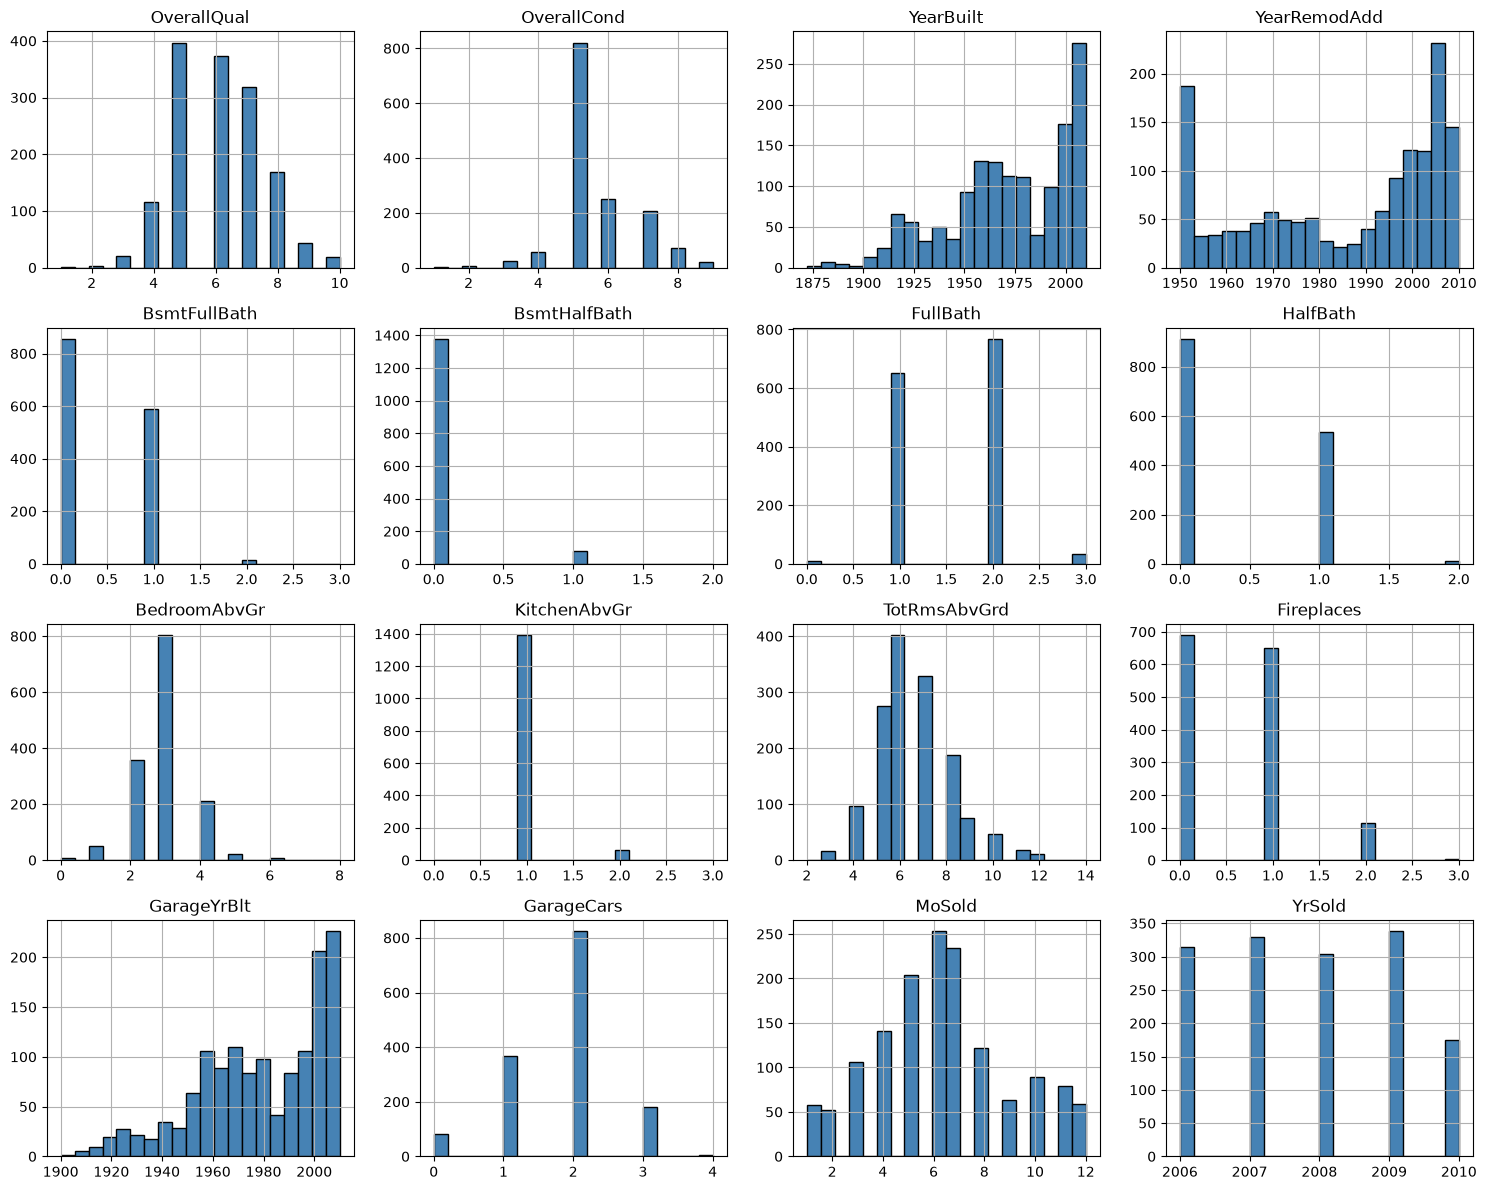

In [19]:
df[discrete_cols].hist(
    bins=20,
    figsize=(15, 12),
    color='steelblue',
    edgecolor='black'
)

plt.tight_layout()
plt.savefig(
    'houseprice_discrete_histogram.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

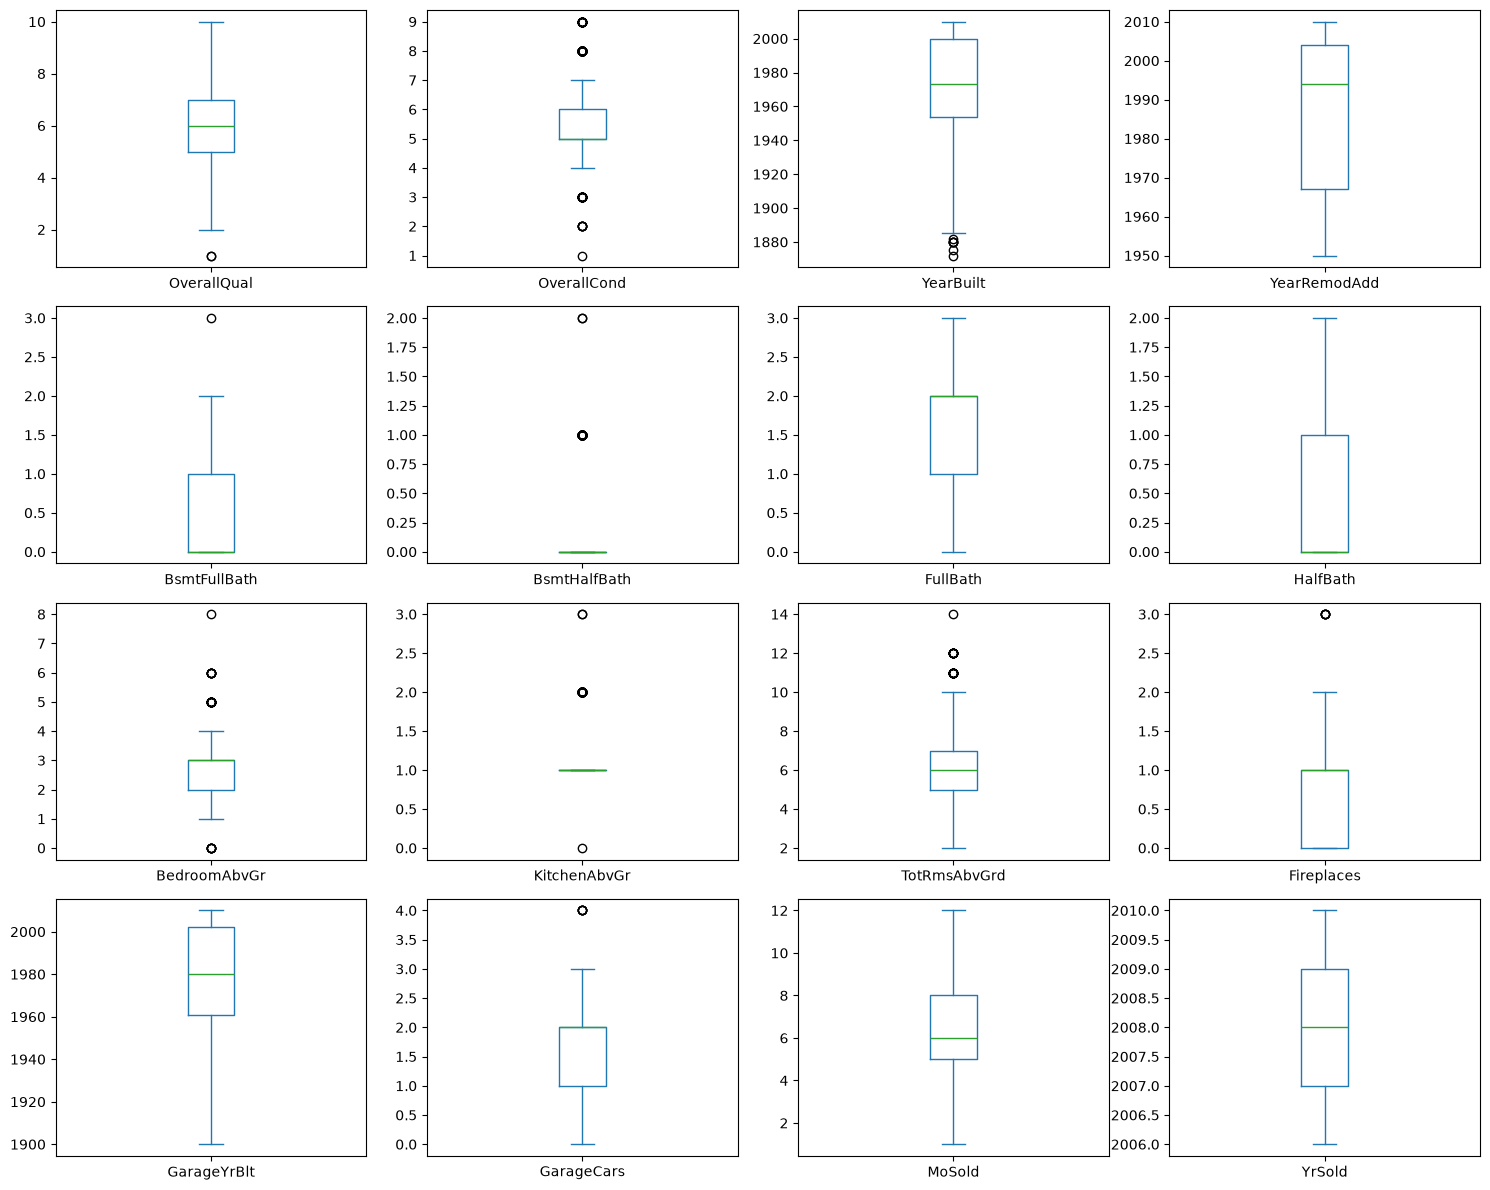

In [20]:
df[discrete_cols].plot(
    kind='box',
    subplots=True,
    layout=(4, 4),
    figsize=(15, 12),
    sharex=False,
    sharey=False
)

plt.tight_layout()
plt.savefig(
    'houseprice_discrete_boxplot.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

### Nominal

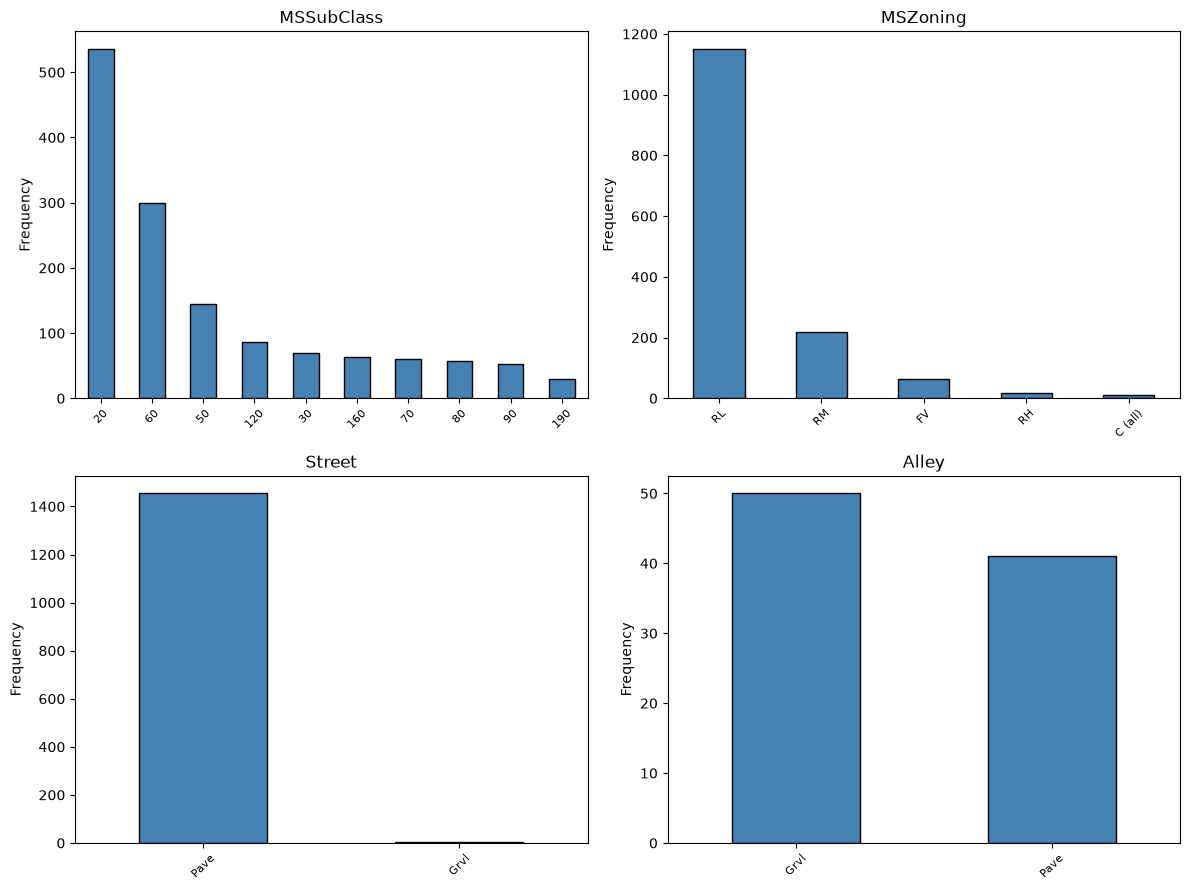

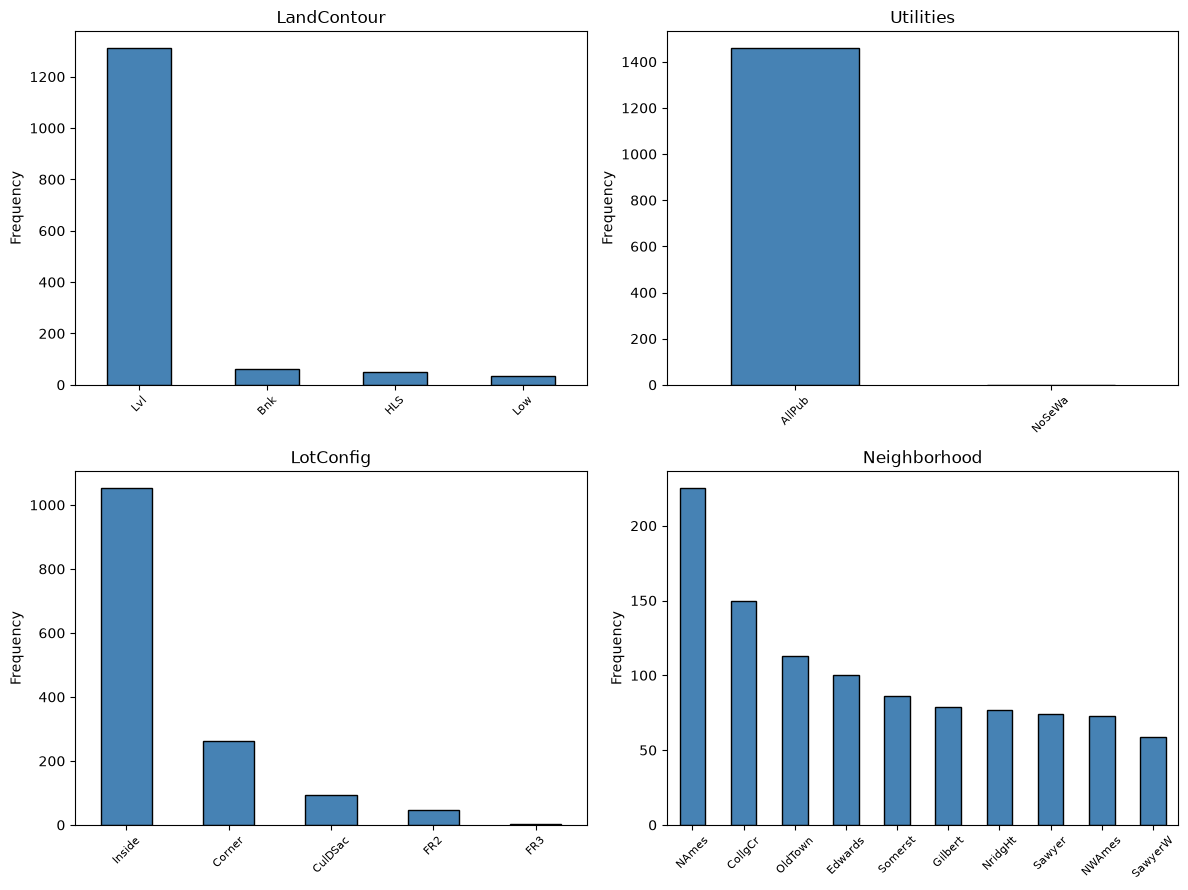

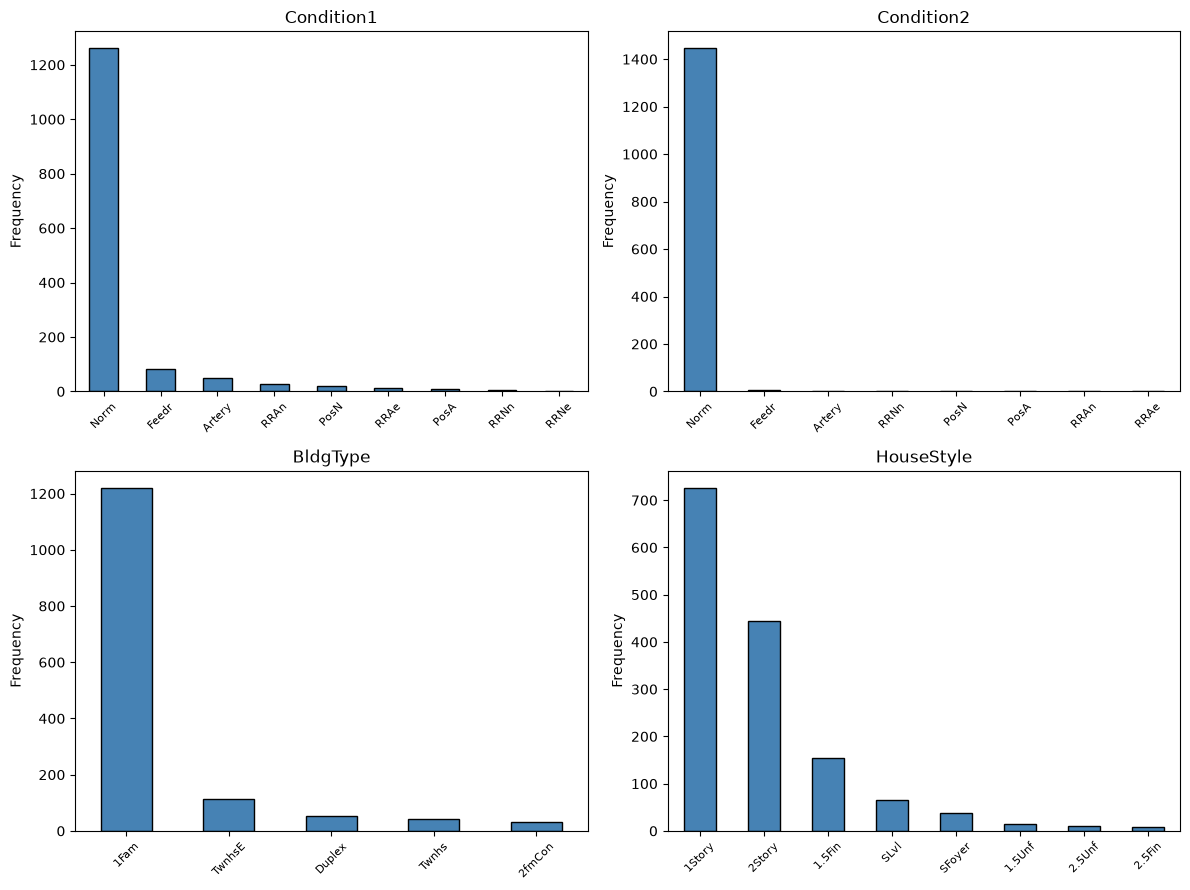

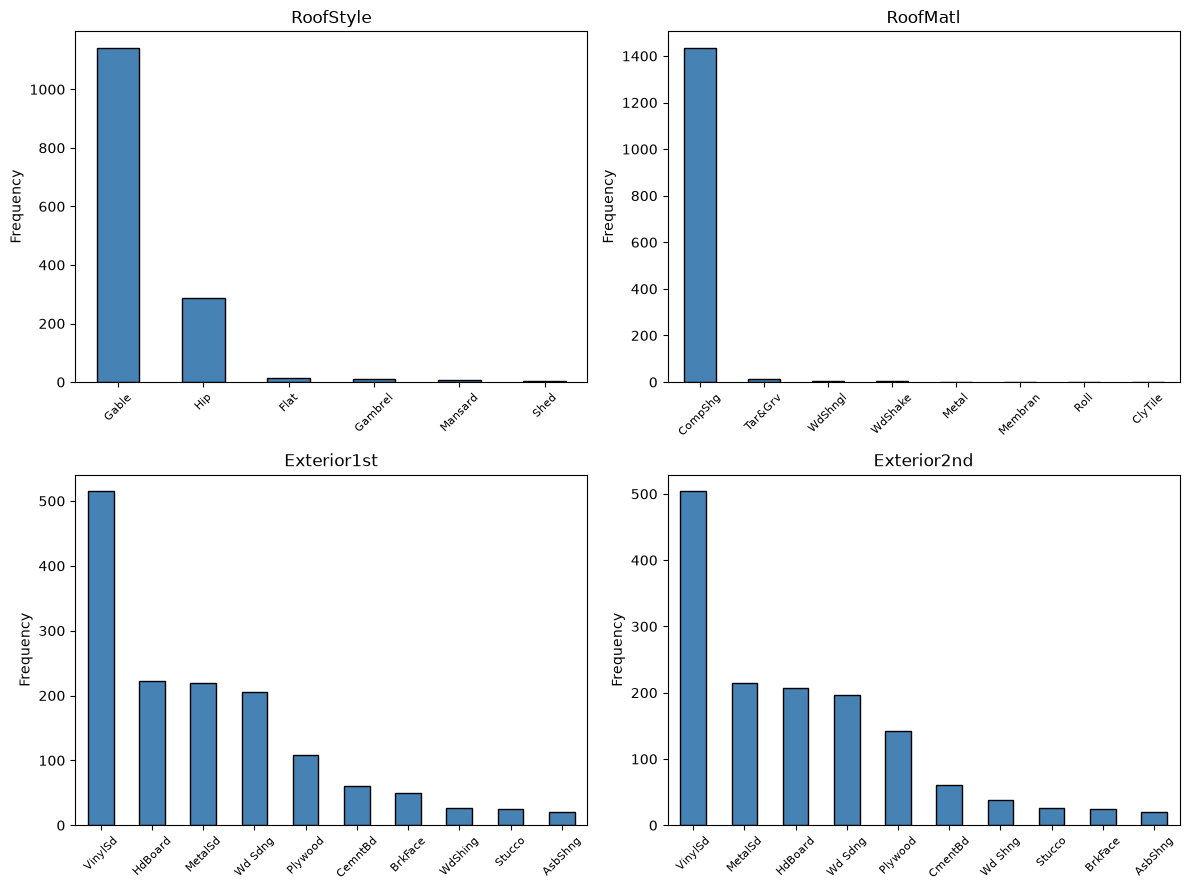

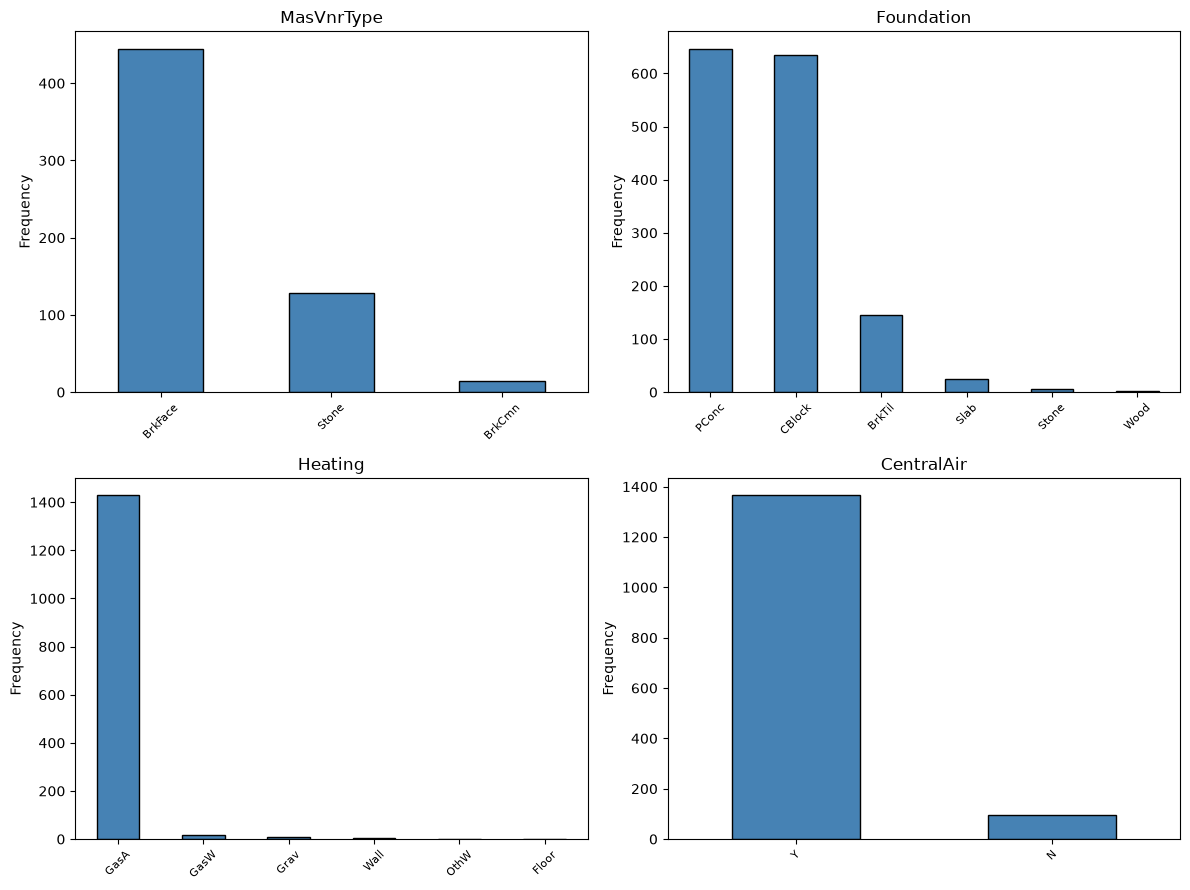

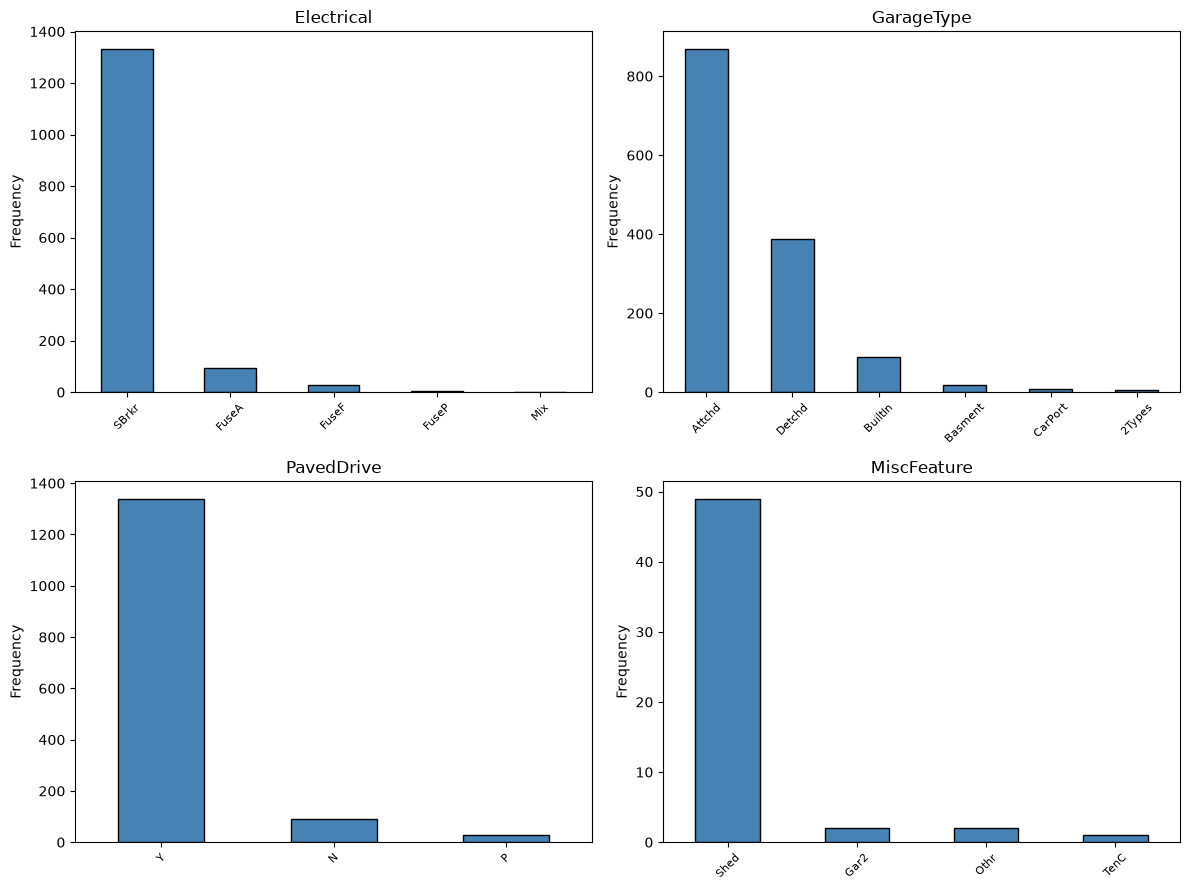

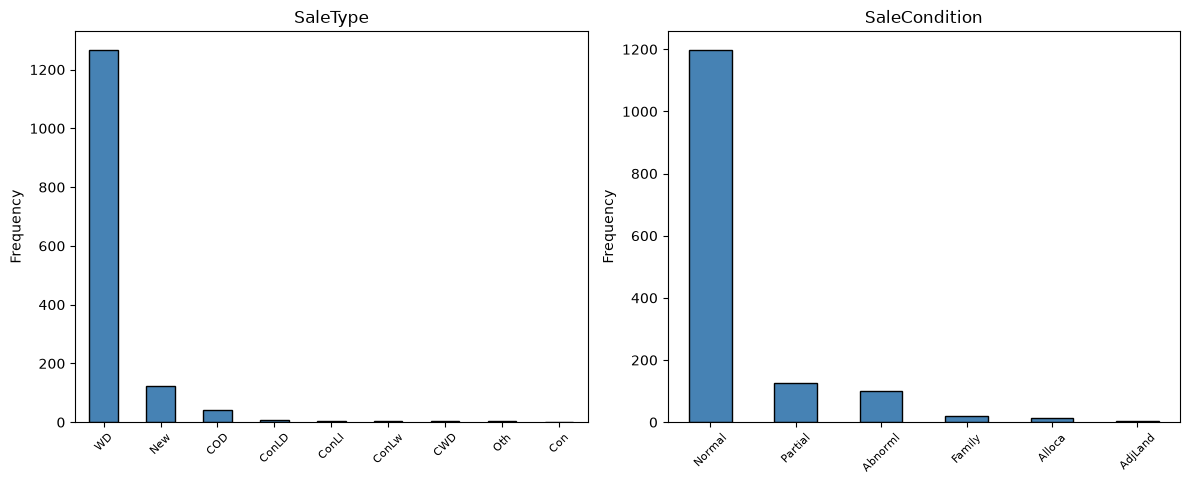

In [21]:
for start in range(0, len(nominal_cols), 4):
    cols = nominal_cols[start:start + 4]

    fig, axes = plt.subplots(2, 2, figsize=(12, 9))
    axes = axes.flatten()

    for ax, col in zip(axes, cols):
        df[col].value_counts().head(10).plot(
            kind='bar',
            ax=ax,
            color='steelblue',
            edgecolor='black'
        )

        ax.set_title(col)
        ax.tick_params(
            axis='x',
            labelrotation=45,
            labelsize=8
        )
        ax.set_xlabel('')
        ax.set_ylabel('Frequency')

    for ax in axes[len(cols):]:
        fig.delaxes(ax)

    plt.tight_layout()
    plt.savefig(
        f'houseprice_nominal_{start // 4 + 1}.png',
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()
    plt.close()

### Ordinal

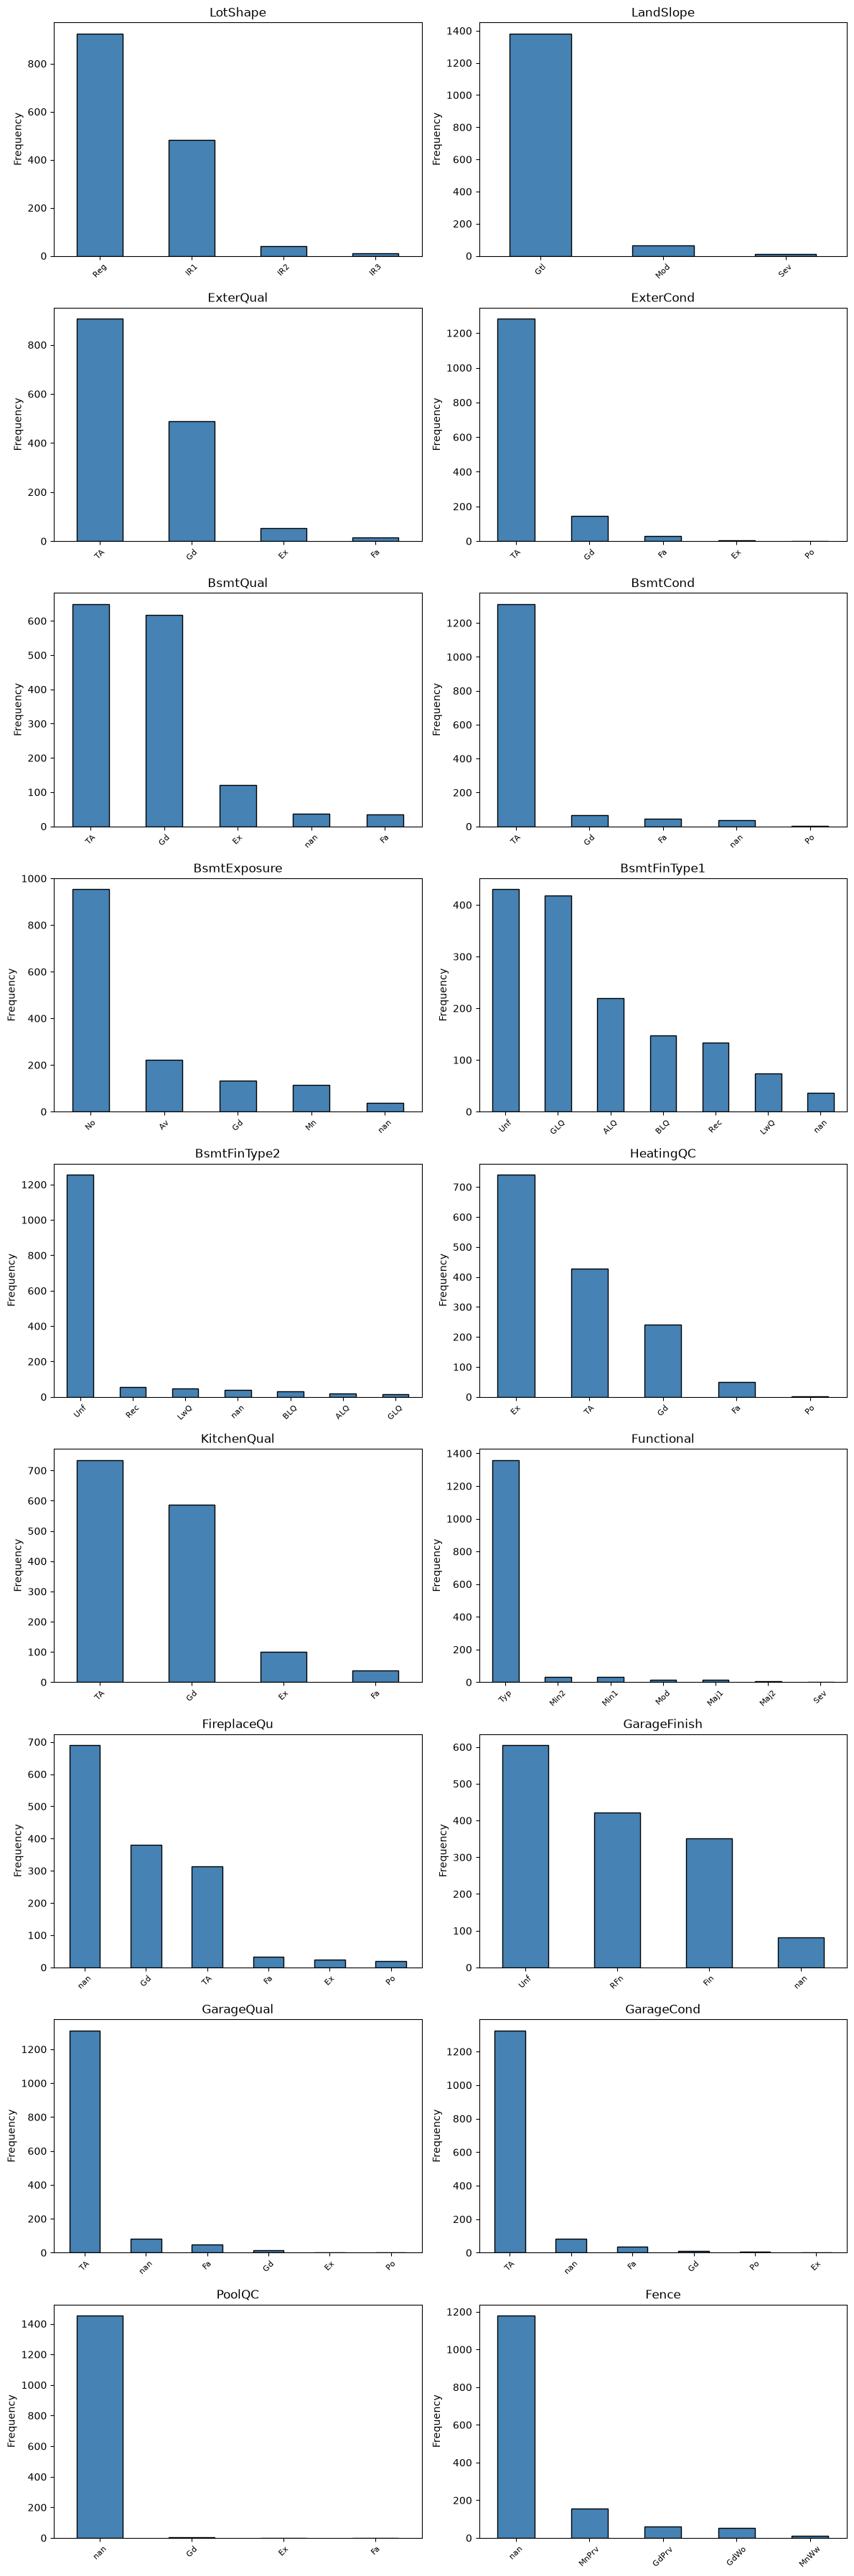

In [22]:
n_cols = 2
n_rows = math.ceil(len(ordinal_cols) / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(12, n_rows * 4)
)

axes = np.array(axes).flatten()

for ax, col in zip(axes, ordinal_cols):
    df[col].value_counts(dropna=False).head(10).plot(
        kind='bar',
        ax=ax,
        color='steelblue',
        edgecolor='black'
    )

    ax.set_title(col)
    ax.tick_params(
        axis='x',
        labelrotation=45,
        labelsize=8
    )
    ax.set_xlabel('')
    ax.set_ylabel('Frequency')

for ax in axes[len(ordinal_cols):]:
    fig.delaxes(ax)

plt.tight_layout()
plt.savefig(
    'houseprice_all_ordinal.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()
plt.close()

# Phân tích đa biến

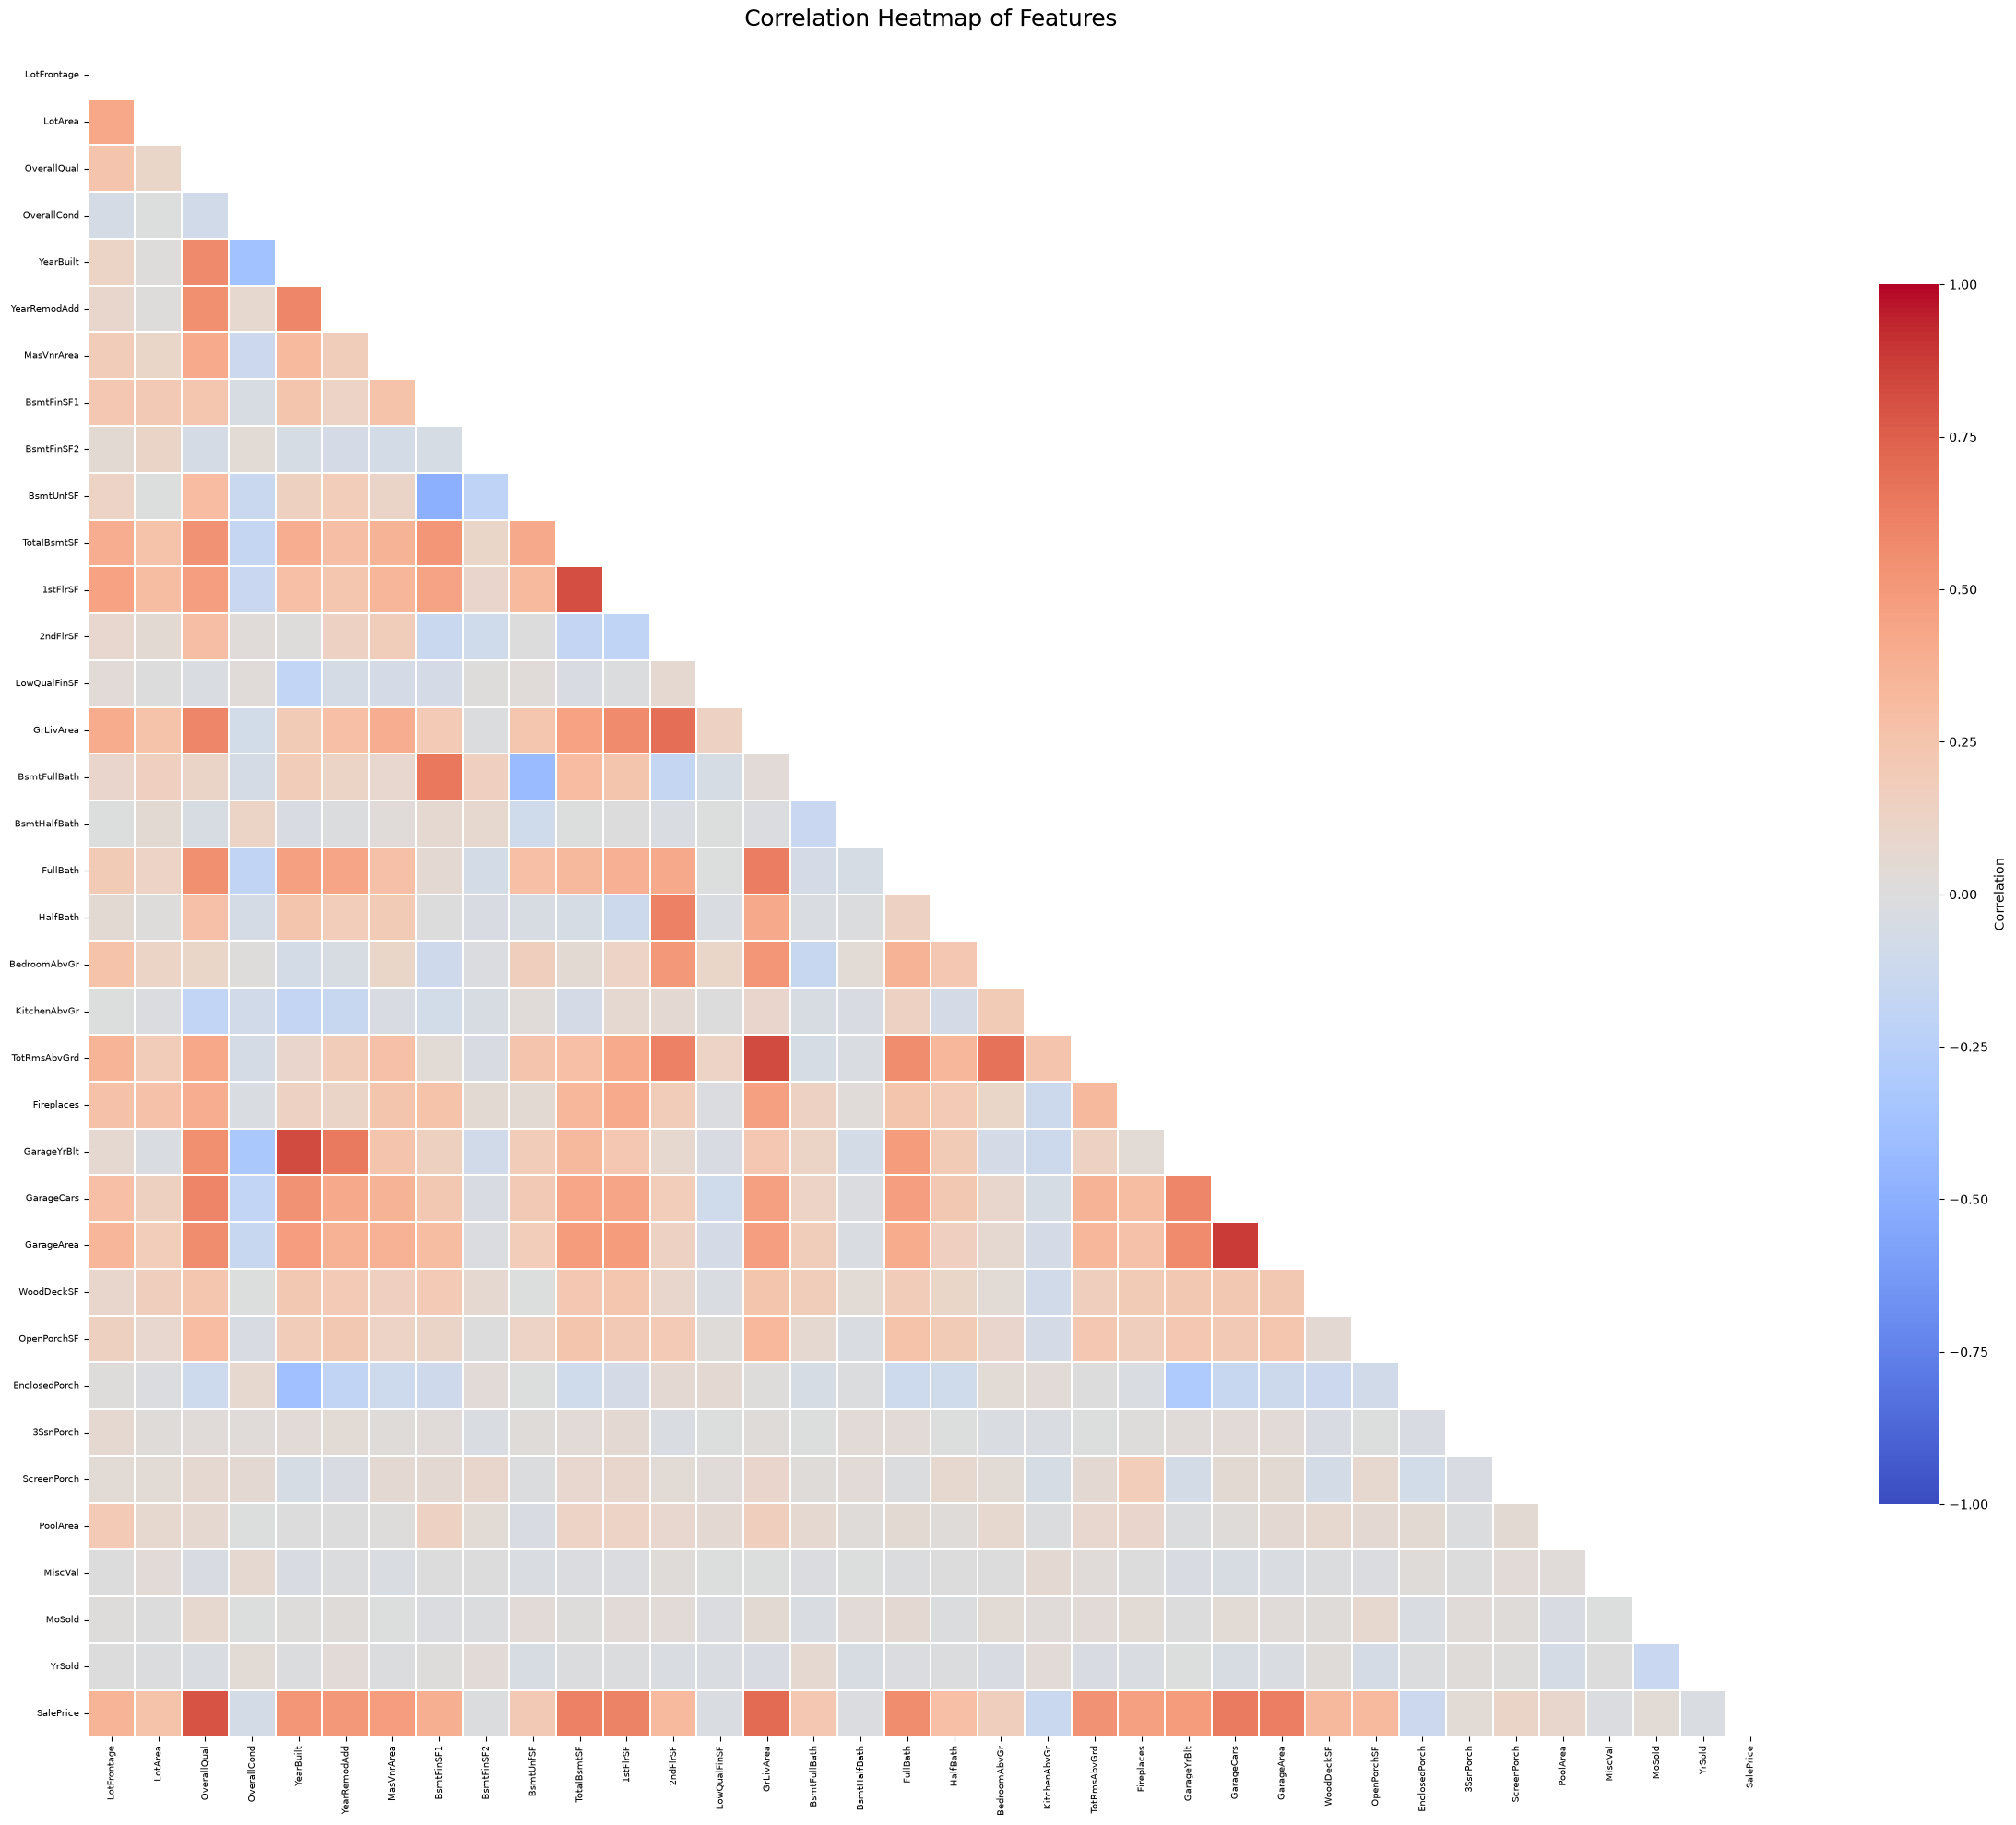

In [23]:
features = df.select_dtypes(
    include=[np.number]
).drop(
    columns=['Id', 'MSSubClass'],
    errors='ignore'
)

corr = features.corr()

plt.figure(figsize=(24, 20))

mask = np.triu(
    np.ones_like(corr, dtype=bool)
)

sns.heatmap(
    corr,
    mask=mask,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.2,
    annot=False,
    cbar_kws={
        'shrink': 0.7,
        'label': 'Correlation'
    }
)

plt.title(
    'Correlation Heatmap of Features',
    fontsize=18,
    pad=20
)

plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)

plt.tight_layout()

plt.savefig(
    'houseprice_correlation_heatmap.png',
    dpi=500,
    bbox_inches='tight'
)

plt.show()
plt.close()

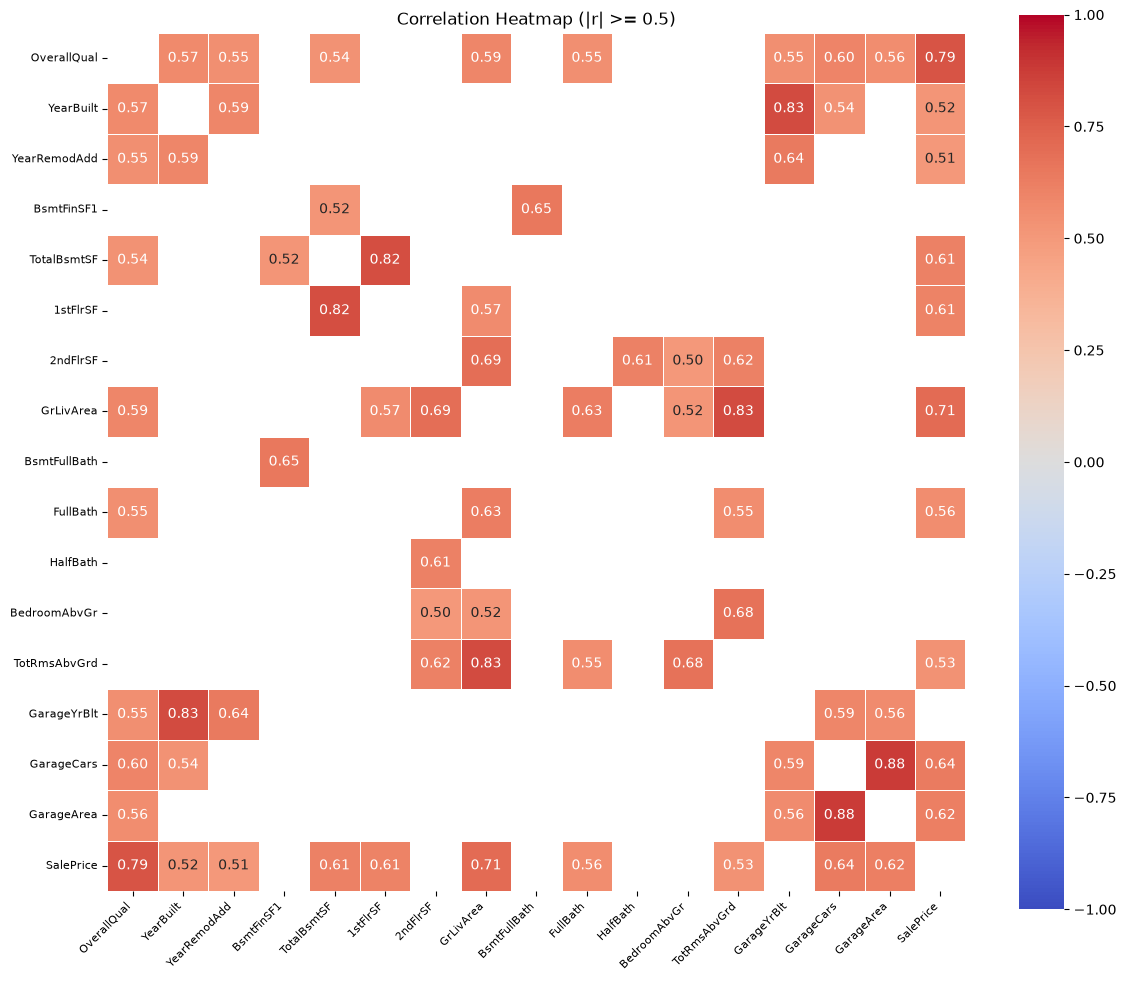

In [26]:
# Tính ma trận tương quan
corr = df.corr(numeric_only=True)

threshold = 0.5

# Chỉ giữ tương quan mạnh
corr_filtered = corr.where(corr.abs() >= threshold).copy()

# Loại bỏ đường chéo chính mà không chỉnh sửa trực tiếp NumPy array
corr_filtered = corr_filtered.mask(
    np.eye(len(corr_filtered), dtype=bool)
)

# Bỏ các hàng và cột không có tương quan đạt ngưỡng
corr_filtered = corr_filtered.dropna(axis=0, how='all')
corr_filtered = corr_filtered.dropna(axis=1, how='all')

# Vẽ biểu đồ
if not corr_filtered.empty:
    plt.figure(figsize=(12, 10))

    sns.heatmap(
        corr_filtered,
        cmap='coolwarm',
        center=0,
        vmin=-1,
        vmax=1,
        annot=True,
        fmt='.2f',
        linewidths=0.5,
        square=True
    )

    plt.title(
        f'Correlation Heatmap (|r| >= {threshold})'
    )

    plt.xticks(rotation=45, ha='right', fontsize=8)
    plt.yticks(rotation=0, fontsize=8)

    plt.tight_layout()

    plt.savefig(
        'houseprice_correlation_filtered.png',
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()
else:
    print('Không có cặp biến nào đạt ngưỡng tương quan.')

## Tương quan giữa các đặc trưng và SalePrice

In [ ]:
sale_corr = corr['SalePrice'].drop(
    'SalePrice'
).sort_values(
    ascending=False
)

print(sale_corr)

OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
GarageYrBlt      0.486362
MasVnrArea       0.477493
Fireplaces       0.466929
BsmtFinSF1       0.386420
LotFrontage      0.351799
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePrice, dtype: float64


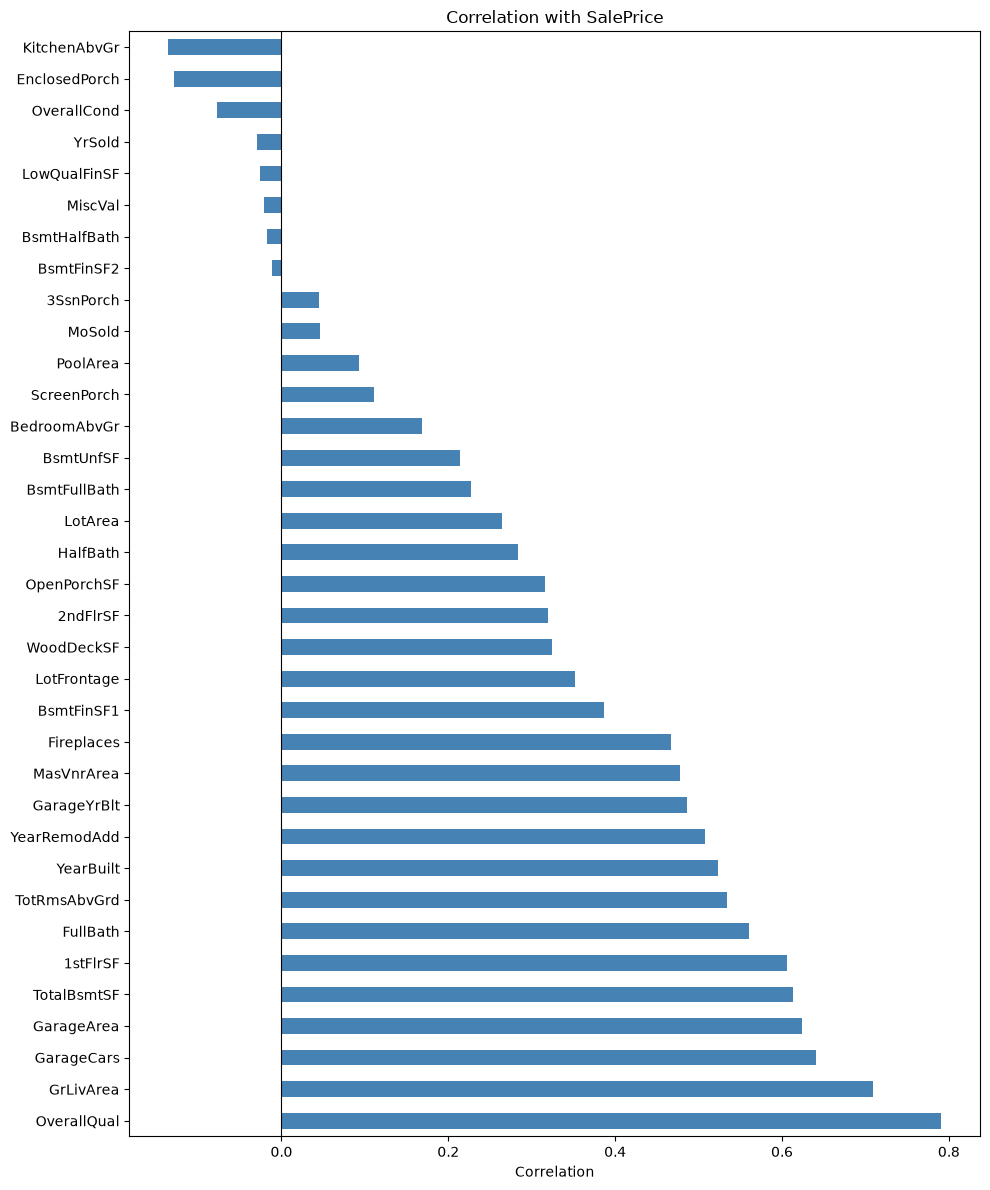

In [ ]:
plt.figure(figsize=(10, 12))

sale_corr.plot(
    kind='barh',
    color='steelblue'
)

plt.axvline(0, color='black', linewidth=0.8)

plt.title('Correlation with SalePrice')
plt.xlabel('Correlation')

plt.tight_layout()

plt.savefig(
    'houseprice_saleprice_correlation.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

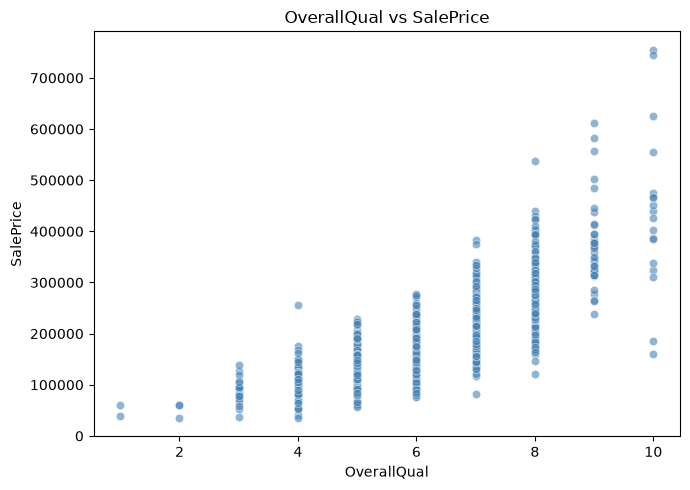

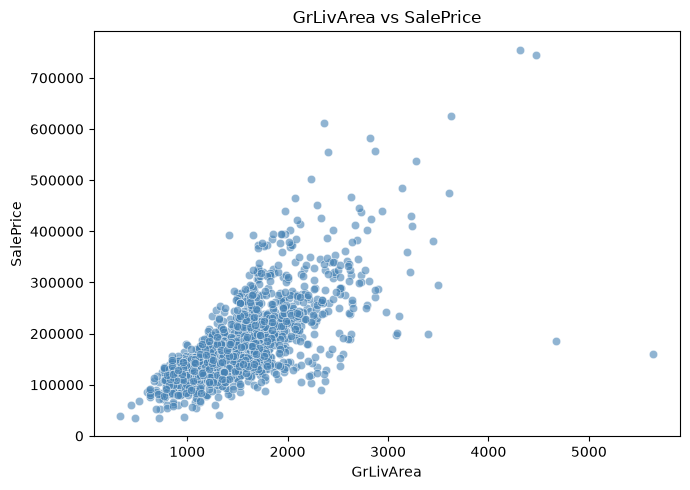

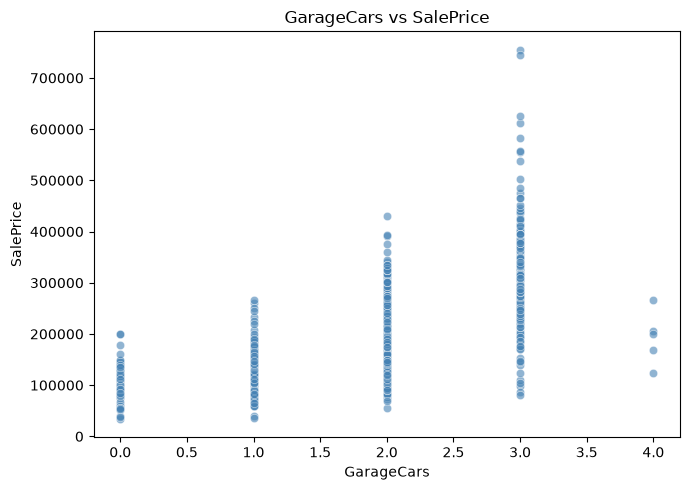

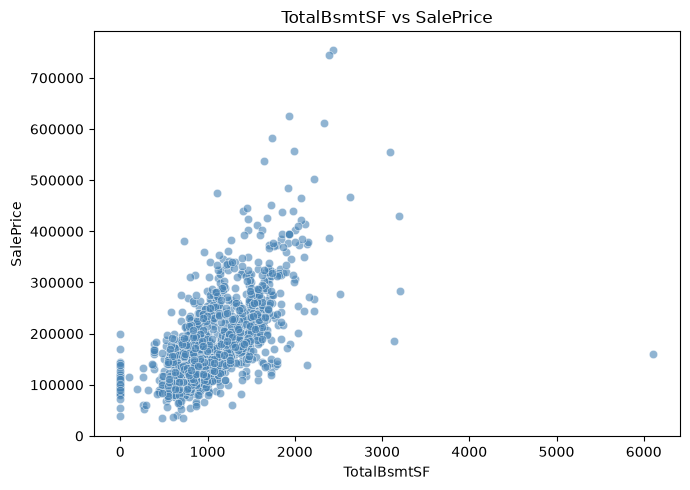

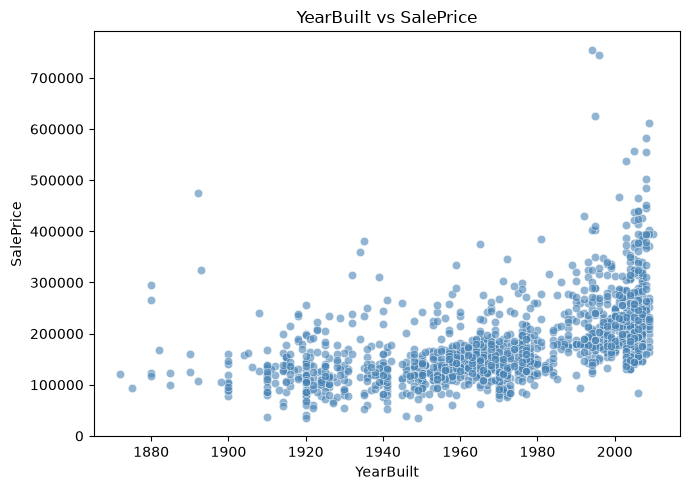

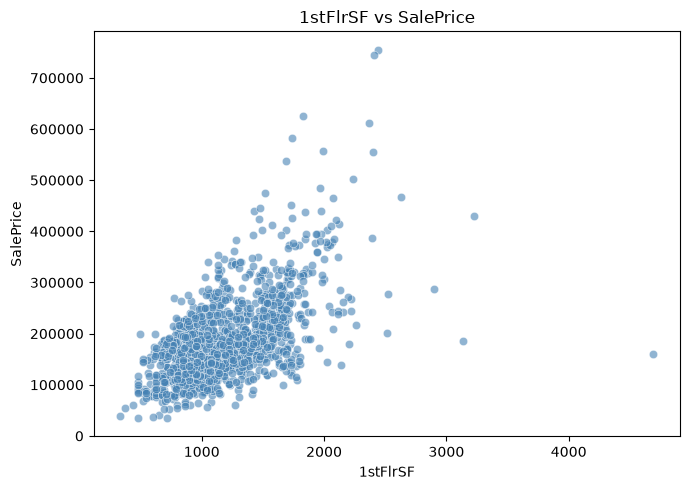

In [ ]:
important_cols = [
    'OverallQual',
    'GrLivArea',
    'GarageCars',
    'TotalBsmtSF',
    'YearBuilt',
    '1stFlrSF'
]

for col in important_cols:
    plt.figure(figsize=(7, 5))

    sns.scatterplot(
        data=df,
        x=col,
        y='SalePrice',
        color='steelblue',
        alpha=0.6
    )

    plt.title(f'{col} vs SalePrice')

    plt.tight_layout()
    plt.show()

# Giá trị thiếu

In [ ]:
missing_report = pd.DataFrame({
    'NaN': df.isna().sum(),
    '?': df.astype('string').eq('?').sum()
})

missing_report['Tổng thiếu'] = (
    missing_report['NaN'] + missing_report['?']
)

missing_report['Tỷ lệ thiếu (%)'] = (
    missing_report['Tổng thiếu'] / len(df) * 100
).round(2)

missing_report = missing_report[
    missing_report['Tổng thiếu'] > 0
].sort_values(
    'Tổng thiếu',
    ascending=False
)

print(missing_report)

               NaN  ?  Tổng thiếu  Tỷ lệ thiếu (%)
PoolQC        1453  0        1453            99.52
MiscFeature   1406  0        1406             96.3
Alley         1369  0        1369            93.77
Fence         1179  0        1179            80.75
MasVnrType     872  0         872            59.73
FireplaceQu    690  0         690            47.26
LotFrontage    259  0         259            17.74
GarageType      81  0          81             5.55
GarageYrBlt     81  0          81             5.55
GarageFinish    81  0          81             5.55
GarageQual      81  0          81             5.55
GarageCond      81  0          81             5.55
BsmtExposure    38  0          38              2.6
BsmtFinType2    38  0          38              2.6
BsmtQual        37  0          37             2.53
BsmtCond        37  0          37             2.53
BsmtFinType1    37  0          37             2.53
MasVnrArea       8  0           8             0.55
Electrical       1  0          

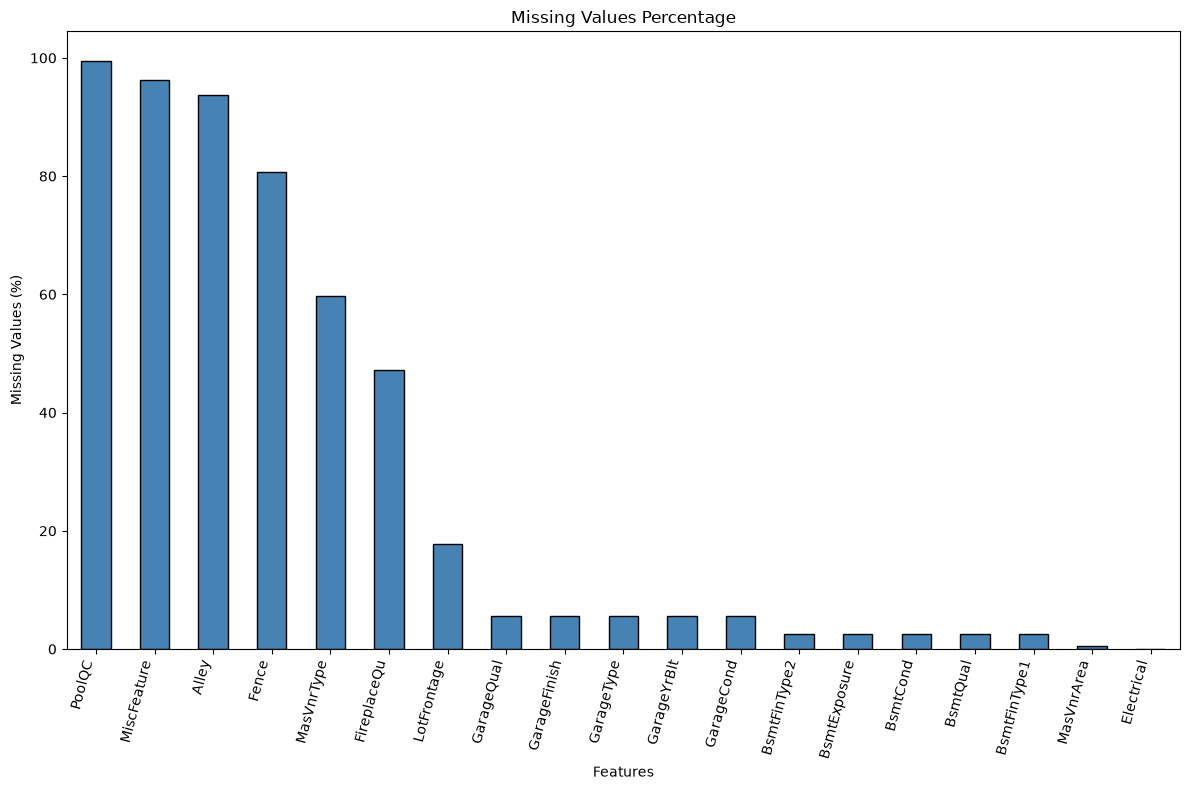

In [ ]:
missing_percent = (
    df.isna().mean() * 100
).sort_values(
    ascending=False
)

missing_percent = missing_percent[
    missing_percent > 0
]

plt.figure(figsize=(12, 8))

missing_percent.plot(
    kind='bar',
    color='steelblue',
    edgecolor='black'
)

plt.title('Missing Values Percentage')
plt.xlabel('Features')
plt.ylabel('Missing Values (%)')

plt.xticks(rotation=75, ha='right')

plt.tight_layout()

plt.savefig(
    'houseprice_missing_values.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [ ]:
absence_cols = [
    'Alley',
    'PoolQC',
    'Fence',
    'MiscFeature',
    'FireplaceQu',
    'GarageType',
    'GarageFinish',
    'GarageQual',
    'GarageCond',
    'BsmtQual',
    'BsmtCond',
    'BsmtExposure',
    'BsmtFinType1',
    'BsmtFinType2'
]

absence_cols = [
    col for col in absence_cols
    if col in df.columns
]

for col in absence_cols:
    print(f'\n--- {col} ---')

    print('Số lượng NaN:', df[col].isna().sum())

    print(
        'Tỷ lệ NaN (%):',
        round(df[col].isna().mean() * 100, 2)
    )


--- Alley ---
Số lượng NaN: 1369
Tỷ lệ NaN (%): 93.77

--- PoolQC ---
Số lượng NaN: 1453
Tỷ lệ NaN (%): 99.52

--- Fence ---
Số lượng NaN: 1179
Tỷ lệ NaN (%): 80.75

--- MiscFeature ---
Số lượng NaN: 1406
Tỷ lệ NaN (%): 96.3

--- FireplaceQu ---
Số lượng NaN: 690
Tỷ lệ NaN (%): 47.26

--- GarageType ---
Số lượng NaN: 81
Tỷ lệ NaN (%): 5.55

--- GarageFinish ---
Số lượng NaN: 81
Tỷ lệ NaN (%): 5.55

--- GarageQual ---
Số lượng NaN: 81
Tỷ lệ NaN (%): 5.55

--- GarageCond ---
Số lượng NaN: 81
Tỷ lệ NaN (%): 5.55

--- BsmtQual ---
Số lượng NaN: 37
Tỷ lệ NaN (%): 2.53

--- BsmtCond ---
Số lượng NaN: 37
Tỷ lệ NaN (%): 2.53

--- BsmtExposure ---
Số lượng NaN: 38
Tỷ lệ NaN (%): 2.6

--- BsmtFinType1 ---
Số lượng NaN: 37
Tỷ lệ NaN (%): 2.53

--- BsmtFinType2 ---
Số lượng NaN: 38
Tỷ lệ NaN (%): 2.6


# Kiểm tra outlier

In [ ]:
outlier_cols = continuous_cols + discrete_cols

outlier_cols = list(
    dict.fromkeys(outlier_cols)
)

outlier_data = df[outlier_cols].apply(
    pd.to_numeric,
    errors='coerce'
)

outlier_report = []

for col in outlier_cols:

    data = outlier_data[col].dropna()

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = data[
        (data < lower) | (data > upper)
    ]

    outlier_report.append({
        'Biến': col,
        'Min': data.min(),
        'Max': data.max(),
        'Ngưỡng dưới': lower,
        'Ngưỡng trên': upper,
        'Số outlier': len(outliers),
        'Tỷ lệ outlier (%)': round(
            len(outliers) / len(data) * 100, 2
        )
    })

outlier_report = pd.DataFrame(
    outlier_report
)

outlier_report = outlier_report.sort_values(
    'Tỷ lệ outlier (%)',
    ascending=False
)

print(
    outlier_report.to_string(index=False)
)

         Biến     Min      Max  Ngưỡng dưới  Ngưỡng trên  Số outlier  Tỷ lệ outlier (%)
EnclosedPorch     0.0    552.0        0.000        0.000         208              14.25
   BsmtFinSF2     0.0   1474.0        0.000        0.000         167              11.44
  OverallCond     1.0      9.0        3.500        7.500         125               8.56
  ScreenPorch     0.0    480.0        0.000        0.000         116               7.95
  LotFrontage    21.0    313.0       27.500      111.500          88               7.33
   MasVnrArea     0.0   1600.0     -249.000      415.000          96               6.61
 BsmtHalfBath     0.0      2.0        0.000        0.000          82               5.62
  OpenPorchSF     0.0    547.0     -102.000      170.000          77               5.27
      LotArea  1300.0 215245.0     1481.500    17673.500          69               4.73
 KitchenAbvGr     0.0      3.0        1.000        1.000          68               4.66
  TotalBsmtSF     0.0   6110.0  

In [ ]:
data = df['SalePrice'].dropna()

Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

saleprice_outliers = df[
    (df['SalePrice'] < lower) |
    (df['SalePrice'] > upper)
]

print('Q1:', Q1)
print('Q3:', Q3)
print('IQR:', IQR)

print('Ngưỡng dưới:', lower)
print('Ngưỡng trên:', upper)

print('Số outlier:', len(saleprice_outliers))

print('\nCác căn nhà có SalePrice cao nhất:')
print(
    saleprice_outliers[
        ['Id', 'SalePrice', 'OverallQual', 'GrLivArea']
    ].sort_values(
        'SalePrice',
        ascending=False
    ).head(20)
)

Q1: 129975.0
Q3: 214000.0
IQR: 84025.0
Ngưỡng dưới: 3937.5
Ngưỡng trên: 340037.5
Số outlier: 61

Các căn nhà có SalePrice cao nhất:
        Id  SalePrice  OverallQual  GrLivArea
691    692     755000           10       4316
1182  1183     745000           10       4476
1169  1170     625000           10       3627
898    899     611657            9       2364
803    804     582933            9       2822
1046  1047     556581            9       2868
440    441     555000           10       2402
769    770     538000            8       3279
178    179     501837            9       2234
798    799     485000            9       3140
185    186     475000           10       3608
1373  1374     466500           10       2633
1243  1244     465000           10       2076
591    592     451950           10       2296
527    528     446261            9       2713
473    474     440000            8       1976
58      59     438780           10       2945
349    350     437154            9      

# Kiểm tra biến không hợp lệ

In [ ]:
for col in discrete_cols:

    s = pd.to_numeric(
        df[col],
        errors='coerce'
    )

    invalid = s.notna() & (
        (s < 0) | (s % 1 != 0)
    )

    print(
        f'{col}: {invalid.sum()} giá trị không hợp lệ'
    )

    if invalid.any():

        print(
            df.loc[
                invalid,
                ['Id', col]
            ].head(10)
        )

OverallQual: 0 giá trị không hợp lệ
OverallCond: 0 giá trị không hợp lệ
YearBuilt: 0 giá trị không hợp lệ
YearRemodAdd: 0 giá trị không hợp lệ
BsmtFullBath: 0 giá trị không hợp lệ
BsmtHalfBath: 0 giá trị không hợp lệ
FullBath: 0 giá trị không hợp lệ
HalfBath: 0 giá trị không hợp lệ
BedroomAbvGr: 0 giá trị không hợp lệ
KitchenAbvGr: 0 giá trị không hợp lệ
TotRmsAbvGrd: 0 giá trị không hợp lệ
Fireplaces: 0 giá trị không hợp lệ
GarageYrBlt: 0 giá trị không hợp lệ
GarageCars: 0 giá trị không hợp lệ
MoSold: 0 giá trị không hợp lệ
YrSold: 0 giá trị không hợp lệ


In [ ]:
nonnegative_cols = [
    'LotFrontage',
    'LotArea',
    'MasVnrArea',
    'BsmtFinSF1',
    'BsmtFinSF2',
    'BsmtUnfSF',
    'TotalBsmtSF',
    '1stFlrSF',
    '2ndFlrSF',
    'LowQualFinSF',
    'GrLivArea',
    'GarageArea',
    'WoodDeckSF',
    'OpenPorchSF',
    'EnclosedPorch',
    '3SsnPorch',
    'ScreenPorch',
    'PoolArea',
    'MiscVal',
    'SalePrice'
]

for col in nonnegative_cols:

    invalid = df[col].notna() & (
        df[col] < 0
    )

    print(
        f'{col}: {invalid.sum()} giá trị âm'
    )

    if invalid.any():

        print(
            df.loc[
                invalid,
                ['Id', col]
            ].head(10)
        )

LotFrontage: 0 giá trị âm
LotArea: 0 giá trị âm
MasVnrArea: 0 giá trị âm
BsmtFinSF1: 0 giá trị âm
BsmtFinSF2: 0 giá trị âm
BsmtUnfSF: 0 giá trị âm
TotalBsmtSF: 0 giá trị âm
1stFlrSF: 0 giá trị âm
2ndFlrSF: 0 giá trị âm
LowQualFinSF: 0 giá trị âm
GrLivArea: 0 giá trị âm
GarageArea: 0 giá trị âm
WoodDeckSF: 0 giá trị âm
OpenPorchSF: 0 giá trị âm
EnclosedPorch: 0 giá trị âm
3SsnPorch: 0 giá trị âm
ScreenPorch: 0 giá trị âm
PoolArea: 0 giá trị âm
MiscVal: 0 giá trị âm
SalePrice: 0 giá trị âm


In [ ]:
checks = {
    'MoSold ngoài khoảng 1-12':
        ~df['MoSold'].between(1, 12),

    'OverallQual ngoài khoảng 1-10':
        ~df['OverallQual'].between(1, 10),

    'OverallCond ngoài khoảng 1-10':
        ~df['OverallCond'].between(1, 10),

    'YearBuilt sau YrSold':
        df['YearBuilt'] > df['YrSold'],

    'YearRemodAdd sau YrSold':
        df['YearRemodAdd'] > df['YrSold']
}

for label, mask in checks.items():

    mask = mask.fillna(False)

    print(
        f'{label}: {mask.sum()} dòng'
    )

    if mask.any():

        print(
            df.loc[
                mask,
                ['Id', 'YearBuilt', 'YearRemodAdd',
                 'MoSold', 'YrSold', 'OverallQual',
                 'OverallCond']
            ].head(10)
        )

MoSold ngoài khoảng 1-12: 0 dòng
OverallQual ngoài khoảng 1-10: 0 dòng
OverallCond ngoài khoảng 1-10: 0 dòng
YearBuilt sau YrSold: 0 dòng
YearRemodAdd sau YrSold: 1 dòng
      Id  YearBuilt  YearRemodAdd  MoSold  YrSold  OverallQual  OverallCond
523  524       2007          2008      10    2007           10            5


# Kiểm tra các biến phân loại

In [ ]:
categorical_cols = nominal_cols + ordinal_cols

for col in categorical_cols:

    print(f'\n--- {col} ---')

    print(
        df[col].value_counts(
            dropna=False
        ).head(15)
    )

    mask = (
        df[col].isna()
        | df[col].astype('string').str.strip().str.lower().isin(
            ['?', 'unknown', 'unknown/invalid',
             'invalid', 'nan']
        )
    )

    if mask.any():

        print('\nCác dòng cần kiểm tra:')

        print(
            df.loc[
                mask,
                ['Id', col]
            ].head(20)
        )

        print(
            f'Tổng số dòng: {mask.sum()}'
        )


--- MSSubClass ---
MSSubClass
20     536
60     299
50     144
120     87
30      69
160     63
70      60
80      58
90      52
190     30
85      20
75      16
45      12
180     10
40       4
Name: count, dtype: int64

--- MSZoning ---
MSZoning
RL         1151
RM          218
FV           65
RH           16
C (all)      10
Name: count, dtype: int64

--- Street ---
Street
Pave    1454
Grvl       6
Name: count, dtype: int64

--- Alley ---
Alley
NaN     1369
Grvl      50
Pave      41
Name: count, dtype: int64

Các dòng cần kiểm tra:
    Id Alley
0    1   NaN
1    2   NaN
2    3   NaN
3    4   NaN
4    5   NaN
5    6   NaN
6    7   NaN
7    8   NaN
8    9   NaN
9   10   NaN
10  11   NaN
11  12   NaN
12  13   NaN
13  14   NaN
14  15   NaN
15  16   NaN
16  17   NaN
17  18   NaN
18  19   NaN
19  20   NaN
Tổng số dòng: 1369

--- LandContour ---
LandContour
Lvl    1311
Bnk      63
HLS      50
Low      36
Name: count, dtype: int64

--- Utilities ---
Utilities
AllPub    1459
NoSeWa       1
Na